## 1 Data Preperation and Descriptive Statistics
- Inputs are the olist_marketing_qualified_leads_dataset.csv, and the olist_closed_deals_dataset.csv

Approach:
 1. Load the files and check the Keys
 2. Join the files using mql_id
 3. Keep the leads starting from December 2017
 4. fix negative days that were loaded in initailly
 5. create the 90 day target from the data
 6. Perform the descriptive statistics on the data

 Output: Lead_Population_90d.csv file for analysis

In [ ]:
import pandas as pd
from scipy import stats

In [ ]:
MQL = pd.read_csv("/content/olist_marketing_qualified_leads_dataset.csv")
DLS = pd.read_csv("/content/olist_closed_deals_dataset.csv")

In [ ]:
#Converting the date columns from text to date.

MQL['first_contact_date'] = pd.to_datetime(MQL['first_contact_date'])
DLS['won_date'] = pd.to_datetime(DLS['won_date'])

In [ ]:
#Important to check every deal actually links to a real unique lead
matched_deals = DLS[DLS['mql_id'].isin(MQL['mql_id'])]
print('Deals Pointing To a Real Lead:', len(matched_deals),'of', len(DLS))


Deals Pointing To a Real Lead: 842 of 842


In [ ]:
# Checking for all duplicates in the datasetsm ensuring that there are no duplicate leads, no leads that have closed twice, and no seller that has been counted twiceprint('Deals Pointing To a Real Lead:', len(matched_deals),'of', len(DLS))

print('Leads:', len(MQL),'rows,', MQL['mql_id'].nunique(), 'unique mql_id')
print('Deals Through mql_id:', len(DLS),'rows,', DLS['mql_id'].nunique(),'unique mql_id')
print('Deals Through seller_id:', len(DLS),'rows,', DLS['seller_id'].nunique(),'unique seller_id')


Leads: 8000 rows, 8000 unique mql_id
Deals Through mql_id: 842 rows, 842 unique mql_id
Deals Through seller_id: 842 rows, 842 unique seller_id


In [ ]:
#Now we join the qualified leads file with the closed deals file

df = MQL.merge(DLS[['mql_id', 'won_date']], on='mql_id', how='left')

print('rows after join:', len(df))
print('leads with a won_date:', df['won_date'].notna().sum())

rows after join: 8000
leads with a won_date: 842


In [ ]:
# Why the data starts in December 2017.
## Leads start in June 2017, but the first recorded win is in December 2017. Leads from before then had no chance to show as converted, so I only use leads from December 2017 onward.

print('first lead:', MQL['first_contact_date'].min().date())
print('first recorded win:', DLS['won_date'].min().date())

first lead: 2017-06-14
first recorded win: 2017-12-05


In [ ]:
#Monthly conversion rate redone from milestone 2

df['converted_ever'] = df['won_date'].notna().astype(int)
df['month'] = df['first_contact_date'].dt.strftime('%Y-%m')

monthly = df.groupby('month').agg(leads=('mql_id', 'size'),
                                  conv=('converted_ever', 'sum'))
monthly['rate'] = (100 * monthly['conv'] / monthly['leads']).round(1)
print(monthly)

         leads  conv  rate
month                     
2017-06      4     0   0.0
2017-07    239     2   0.8
2017-08    386     9   2.3
2017-09    312     7   2.2
2017-10    416    14   3.4
2017-11    445    18   4.0
2017-12    200    11   5.5
2018-01   1141   152  13.3
2018-02   1028   149  14.5
2018-03   1174   167  14.2
2018-04   1352   183  13.5
2018-05   1303   130  10.0


In [ ]:
#Creating the cutoff date from December 2017 and onwards and checking the measure of the most successful amount of days to convert.

df = df[df['first_contact_date'] >= '2017-12-01'].reset_index(drop=True)
df['days_to_convert'] = (df['won_date'] - df['first_contact_date']).dt.days

conv = df[df['won_date'].notna()]
print('leads:', len(df), '| converted:', len(conv))
print('negative days:', (conv['days_to_convert'] < 0).sum())
print(conv['days_to_convert'].describe().round(1))
print()
for n in [30, 60, 90, 120, 150]:
    share = 100 * (conv['days_to_convert'] <= n).mean()
    print(f'within {n} days: {share}% of conversions')


leads: 6198 | converted: 792
negative days: 1
count    792.0
mean      36.9
std       55.2
min       -2.0
25%        5.0
50%       13.0
75%       40.0
max      321.0
Name: days_to_convert, dtype: float64

within 30 days: 69.82323232323232% of conversions
within 60 days: 81.18686868686868% of conversions
within 90 days: 86.36363636363636% of conversions
within 120 days: 90.65656565656566% of conversions
within 150 days: 93.3080808080808% of conversions


In [ ]:
# The error found above of a lead being successful before the first contact date is wrong, that it not possible, the error has been fixed there are no negative days anymore

df['days_to_convert'] = df['days_to_convert'].clip(lower=0)
print('negative days after fixing the error:', (df['days_to_convert'] < 0).sum())

negative days after fixing the error: 0


mean: 36.9
median: 13.0
mode: 1.0
variance: 3044.2


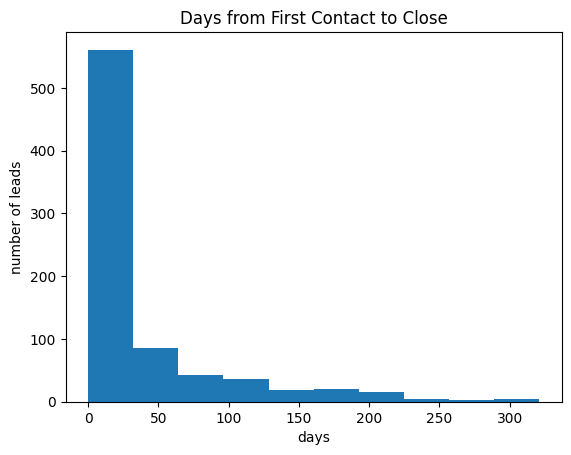

In [ ]:
#For the descriptive statistics, I calculated the mean, median, and mode of the dataset on the amount of days to close from the first contact date. The histogram also shows a visualization of the results

import matplotlib.pyplot as plt

print('mean:', round(df['days_to_convert'].mean(), 1))
print('median:', df['days_to_convert'].median())
print('mode:', df['days_to_convert'].mode()[0])
print('variance:', round(df['days_to_convert'].var(), 1))

df['days_to_convert'].plot(kind='hist')

plt.title('Days from First Contact to Close')
plt.xlabel('days')
plt.ylabel('number of leads')
plt.show()

In [ ]:
#before I decide to create the 90 day success target, I need to ensure that every lead had at least 90 days or more to convert

N = 90

data_end = df['won_date'].max()
last_lead = df['first_contact_date'].max()
print('Data ends:', data_end.date(), '| last lead:', last_lead.date())
print('Days of follow-up for last lead:', (data_end - last_lead).days)
print('Window fully observed for every lead:', (data_end - last_lead).days >= N)


Data ends: 2018-11-14 | last lead: 2018-05-31
Days of follow-up for last lead: 167
Window fully observed for every lead: True


In [ ]:
#Finally we can create the 90 day target for analysis

df['converted'] = (df['days_to_convert'] <= N).astype(int)

print('Leads:', len(df))
print('Converted within', N, 'days:', df['converted'].sum())
print('Conversion rate:', round(100 * df['converted'].mean(), 2), '%')
print('Conversions after', N, 'days (counted as 0):', df['converted_ever'].sum() - df['converted'].sum())


Leads: 6198
Converted within 90 days: 684
Conversion rate: 11.04 %
Conversions after 90 days (counted as 0): 108


In [ ]:
#Now we have the Lead_Population_90d file that can be used to answer the research questions.

df.to_csv('Lead_Population_90d.csv', index=False)